In [2]:
import matplotlib.pyplot as plt
import numpy as np
import os

In [6]:
data_tag = 'treasure_box_sw'

summary_1_false = np.loadtxt(os.path.join(os.path.abspath(''), 'results', data_tag, 'summary_1_false.txt'))
summary_1_true = np.loadtxt(os.path.join(os.path.abspath(''), 'results', data_tag, 'summary_1_true.txt'))
summary_11_false = np.loadtxt(os.path.join(os.path.abspath(''), 'results', data_tag, 'summary_11_false.txt'))
summary_11_true = np.loadtxt(os.path.join(os.path.abspath(''), 'results', data_tag, 'summary_11_true.txt'))

In [142]:
indices = [0]
indices += [int((i / 20)*1000) for i in range(1, 20)]
indices += [-4, -3, -2, -1]

summary = np.zeros((len(indices), 4), dtype=int)

for i, index in enumerate(indices):
    summary[i, 0] = summary_11_true[index]
    summary[i, 1] = summary_1_true[index]
    summary[i, 2] = summary_11_false[index]
    summary[i, 3] = summary_1_false[index]

header = "{:s} & {:s} & {:s} & {:s} & {:s} \\\\ \hline".format("\\textbf{Success rate}",
                                                               "\\textbf{10+1 Draws, 3x}",
                                                               "\\textbf{1 Draw, 3x}",
                                                               "\\textbf{10+1 Draws, No 3x}",
                                                               "\\textbf{1 Draw, No 3x}")
print(header)

row_names = ["Mean"]
row_names += ["{:d}\\%".format(5*i) for i in range(1, 20)]
row_names += ["99\\%", "99.9\\%", "99.99\\%", "99.999\\%", "99.9999\\%"]

for i in range(summary.shape[0]):
    print("{:10s} & {:10,d} ({:,d}) & {:10,d} ({:,d}) & {:10,d} ({:,d}) & {:10,d} ({:,d}) \\\\".format(row_names[i],
                                                                                                               summary[i, 0],
                                                                                                               int(round(summary[i, 0] / 11)) * 1000,
                                                                                                               summary[i, 1],
                                                                                                               summary[i, 1] * 100,
                                                                                                               summary[i, 2],
                                                                                                               int(round(summary[i, 2] / 11)) * 1000,
                                                                                                               summary[i, 3],
                                                                                                               summary[i, 3] * 100))

\textbf{Success rate} & \textbf{10+1 Draws, 3x} & \textbf{1 Draw, 3x} & \textbf{10+1 Draws, No 3x} & \textbf{1 Draw, No 3x} \\ \hline
Mean       &      2,759 (251,000) &      3,258 (325,800) &      8,258 (751,000) &      9,773 (977,300) \\
5\%        &        154 (14,000) &        168 (16,800) &        429 (39,000) &        503 (50,300) \\
10\%       &        297 (27,000) &        344 (34,400) &        880 (80,000) &      1,032 (103,200) \\
15\%       &        462 (42,000) &        530 (53,000) &      1,353 (123,000) &      1,590 (159,000) \\
20\%       &        627 (57,000) &        728 (72,800) &      1,848 (168,000) &      2,183 (218,300) \\
25\%       &        803 (73,000) &        938 (93,800) &      2,387 (217,000) &      2,814 (281,400) \\
30\%       &        990 (90,000) &      1,163 (116,300) &      2,948 (268,000) &      3,488 (348,800) \\
35\%       &      1,199 (109,000) &      1,404 (140,400) &      3,564 (324,000) &      4,213 (421,300) \\
40\%       &      1,419 (129,000

<>:13: SyntaxWarning: invalid escape sequence '\h'
<>:13: SyntaxWarning: invalid escape sequence '\h'
C:\Users\buuva\AppData\Local\Temp\ipykernel_3568\3027492840.py:13: SyntaxWarning: invalid escape sequence '\h'
  header = "{:s} & {:s} & {:s} & {:s} & {:s} \\\\ \hline".format("\\textbf{Success rate}",


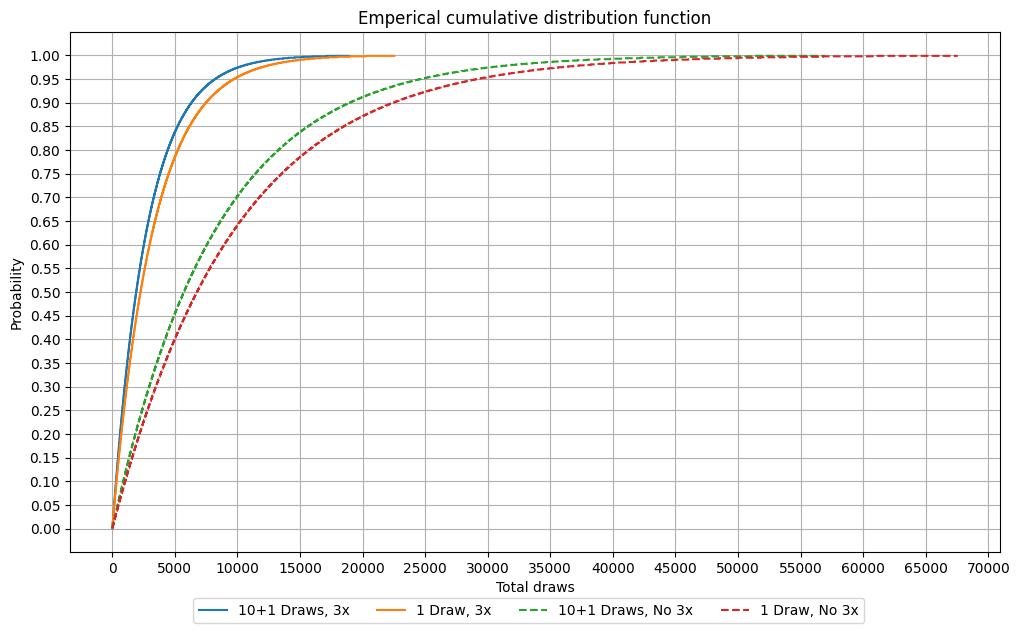

In [143]:
plt.figure(figsize=(12, 6.75))

probabilities = [i/1000 for i in range(1, 1000)]
# probabilities += [1 - 10**-4, 1 - 10**-5, 1 - 10**-6]

plt.step(summary_11_true[1:-3] ,probabilities, label="10+1 Draws, 3x")
plt.step(summary_1_true[1:-3] ,probabilities, label="1 Draw, 3x")
plt.step(summary_11_false[1:-3] ,probabilities, label="10+1 Draws, No 3x", linestyle="--")
plt.step(summary_1_false[1:-3] ,probabilities, label="1 Draw, No 3x", linestyle="--")


plt.xlabel("Total draws")
plt.ylabel("Probability")
plt.title("Emperical cumulative distribution function")

plt.xticks([i*5000 for i in range(int(1.05 * summary[-4, :].max()) // 5000 + 1)])
plt.yticks([i/20 for i in range(21)])

plt.legend(loc="lower left", bbox_to_anchor=(0.125, -0.15), ncols=4)

plt.grid()